# 05 · Modelos de referencia (baselines)

**Objetivo:** fijar el listón que tienen que superar RNN, LSTM y GRU, con exactamente el mismo protocolo de evaluación que usarán ellas.

| Modelo | Predicción del retorno a *h* días | Para qué sirve |
|---|---|---|
| **Ingenuo** (obligatorio) | ŷ = 0 → "el precio futuro = el precio de hoy" | Referencia del enunciado |
| **Media histórica** | ŷ = media de los retornos a *h* días del train | ¿Basta con la tendencia alcista de largo plazo? |
| **Ridge sobre la ventana** | regresión lineal regularizada sobre los mismos 60 días × 16 variables | ¿Aporta algo la **recurrencia** frente a un modelo lineal con la misma información? |

Métricas sobre el **precio en USD** reconstruido: MSE, MAE, RMSE, MAPE, acierto direccional y mejora frente al ingenuo. En test se añade el contraste de **Diebold-Mariano** (¿la diferencia con el ingenuo es estadísticamente significativa?).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge

from oil_forecast.config import HORIZONS, TARGET, TEST_START, VAL_YEARS, WINDOW
from oil_forecast.data import load_dataset, log_return_targets
from oil_forecast.features import FoldScaler, build_features
from oil_forecast.metrics import diebold_mariano, evaluate
from oil_forecast.sequences import make_sequences
from oil_forecast.splits import train_test_split, walk_forward_folds

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 80})
pd.set_option("display.float_format", "{:.2f}".format)
warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1. Datos (mismo preprocesamiento que el notebook 04)

In [2]:
df = load_dataset()
feats = build_features(df)
targets = log_return_targets(df[TARGET], HORIZONS).loc[feats.index]
price = df[TARGET].loc[feats.index].to_numpy()
index = feats.index
X_cols = list(feats.columns)
print(f"{len(index):,} días · {len(X_cols)} variables")

6,113 días · 16 variables


## 2. Protocolo de evaluación

Para cada horizonte y cada partición (5 folds walk-forward + test):
1. Escalador ajustado solo con train.
2. Cada modelo predice el retorno a *h* días desde cada origen → precio = P(t)·exp(ŷ).
3. Métricas en USD frente al precio real P(t+h).

El `alpha` del Ridge se elige con la media de los folds de validación y **después** se aplica una única vez al test (igual que se hará con los hiperparámetros de las redes).

In [3]:
ALPHAS = [10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]

def predict_split(h, train, evaluate_on, alphas=ALPHAS):
    """Returns predicted log-returns of every model for the evaluation origins."""
    y = targets[f"y_{h}"].to_numpy()
    scaler = FoldScaler().fit(feats.iloc[train])
    X = scaler.transform(feats).to_numpy(dtype="float32")
    X_tr, y_tr = make_sequences(X, y, train, WINDOW)
    X_ev, _ = make_sequences(X, y, evaluate_on, WINDOW)
    preds = {"Ingenuo": np.zeros(len(evaluate_on)), "Media histórica": np.full(len(evaluate_on), y[train].mean())}
    for a in alphas:
        model = Ridge(alpha=a).fit(X_tr.reshape(len(X_tr), -1), y_tr)
        preds[f"Ridge(alpha={a})"] = model.predict(X_ev.reshape(len(X_ev), -1))
    return preds

def score(h, origins, preds):
    p_now = price[origins]
    p_true = price[origins + h]
    naive = p_now
    return {name: evaluate(p_now, p_true, p_now * np.exp(r), naive) for name, r in preds.items()}

In [4]:
val_rows = []
for name, h in HORIZONS.items():
    for f in walk_forward_folds(index, h, VAL_YEARS, TEST_START):
        val_pos = f.val[f.val >= WINDOW - 1]
        for model, m in score(h, val_pos, predict_split(h, f.train, val_pos)).items():
            val_rows.append({"horizonte": name, "fold": f.name, "modelo": model, **m})
val = pd.DataFrame(val_rows)
val_mean = val.groupby(["horizonte", "modelo"], sort=False)[["MAE", "RMSE", "Mejora_RMSE_vs_ingenuo_%"]].mean()
best_alpha = {}
for name in HORIZONS:
    ridge = val_mean.loc[name].filter(like="Ridge", axis=0)
    best_alpha[name] = int(ridge["RMSE"].idxmin().split("=")[1].rstrip(")"))
print("Mejor alpha por horizonte (validación walk-forward):", best_alpha)
val_mean

Mejor alpha por horizonte (validación walk-forward): {'corto': 100000, 'medio': 100000, 'largo': 100000}


MAE  RMSE  Mejora_RMSE_vs_ingenuo_%
horizonte modelo                                                     
corto     Ingenuo                3.09  4.11                      0.00
          Media histórica        3.09  4.11                      0.02
          Ridge(alpha=10)        3.56  4.72                    -16.58
          Ridge(alpha=100)       3.42  4.53                    -11.92
          Ridge(alpha=1000)      3.27  4.34                     -6.35
          Ridge(alpha=10000)     3.11  4.14                     -0.72
          Ridge(alpha=100000)    3.08  4.09                      0.35
          Ridge(alpha=1000000)   3.08  4.10                      0.21
          Ridge(alpha=10000000)  3.09  4.11                      0.05
medio     Ingenuo               11.33 14.95                      0.00
          Media histórica       11.45 15.11                     -1.14
          Ridge(alpha=10)       13.79 18.02                    -20.64
          Ridge(alpha=100)      13.03 17.24                    -15.34
          Ridge(alpha=1000)     12.05 16.11                     -7.71
          Ridge(alpha=10000)    11.41 15.22                     -2.18
          Ridge(alpha=100000)   11.24 14.85                      0.62
          Ridge(alpha=1000000)  11.47 15.03                     -0.56
          Ridge(alpha=10000000) 11.45 15.08                     -0.94
largo     Ingenuo               25.67 29.67                      0.00
          Media histórica       27.00 31.01                     -5.87
          Ridge(alpha=10)       41.30 60.32                    -97.01
          Ridge(alpha=100)      28.87 34.64                    -17.79
          Ridge(alpha=1000)     26.58 30.64                     -4.99
          Ridge(alpha=10000)    25.62 29.21                      0.02
          Ridge(alpha=100000)   24.14 28.53                      2.66
          Ridge(alpha=1000000)  25.87 29.81                     -1.72
          Ridge(alpha=10000000) 26.81 30.80                     -5.07

## 3. Resultados en validación walk-forward (media de los folds)

In [5]:
summary_val = []
for name in HORIZONS:
    for model in ["Ingenuo", "Media histórica", f"Ridge(alpha={best_alpha[name]})"]:
        r = val[(val.horizonte == name) & (val.modelo == model)]
        summary_val.append({"horizonte": name, "modelo": model.split("(")[0],
                            "MAE": r.MAE.mean(), "RMSE": r.RMSE.mean(), "RMSE desv. folds": r.RMSE.std(),
                            "Mejora RMSE vs ingenuo %": r["Mejora_RMSE_vs_ingenuo_%"].mean(),
                            "Dirección %": r["Direccion_%"].mean()})
pd.DataFrame(summary_val).set_index(["horizonte", "modelo"])

MAE  RMSE  RMSE desv. folds  \
horizonte modelo                                          
corto     Ingenuo          3.09  4.11              1.75   
          Media histórica  3.09  4.11              1.76   
          Ridge            3.08  4.09              1.74   
medio     Ingenuo         11.33 14.95              3.50   
          Media histórica 11.45 15.11              3.50   
          Ridge           11.24 14.85              3.57   
largo     Ingenuo         25.67 29.67              4.35   
          Media histórica 27.00 31.01              1.08   
          Ridge           24.14 28.53              4.74   

                           Mejora RMSE vs ingenuo %  Dirección %  
horizonte modelo                                                  
corto     Ingenuo                              0.00          NaN  
          Media histórica                      0.02        56.10  
          Ridge                                0.35        56.24  
medio     Ingenuo                              0.00          NaN  
          Media histórica                     -1.14        54.30  
          Ridge                                0.62        52.15  
largo     Ingenuo                              0.00          NaN  
          Media histórica                     -5.87        52.38  
          Ridge                                2.66        50.89

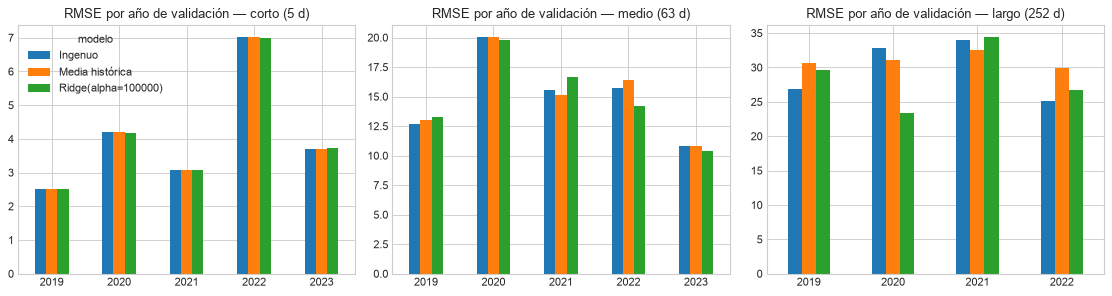

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, name in zip(axes, HORIZONS):
    sub = val[(val.horizonte == name) & val.modelo.isin(["Ingenuo", "Media histórica", f"Ridge(alpha={best_alpha[name]})"])]
    sub.pivot(index="fold", columns="modelo", values="RMSE").plot(kind="bar", ax=ax, legend=(name == "corto"), rot=0)
    ax.set_title(f"RMSE por año de validación — {name} ({HORIZONS[name]} d)"); ax.set_xlabel("")
plt.tight_layout()

## 4. Resultados en test (2024-2026)

Se evalúa una única vez con el `alpha` elegido en validación.

In [7]:
test_rows, test_preds = [], {}
for name, h in HORIZONS.items():
    train, test = train_test_split(index, h, TEST_START)
    preds = predict_split(h, train, test, alphas=[best_alpha[name]])
    preds = {k.split("(")[0]: v for k, v in preds.items()}
    test_preds[name] = (test, preds)
    p_now, p_true = price[test], price[test + h]
    for model, m in score(h, test, preds).items():
        row = {"horizonte": name, "modelo": model, **m}
        if model != "Ingenuo":
            row["DM estadístico"], row["DM p-valor"] = diebold_mariano(p_true - p_now * np.exp(preds[model]), p_true - p_now, h)
        test_rows.append(row)
test_table = pd.DataFrame(test_rows).set_index(["horizonte", "modelo"])
test_table[["MSE", "MAE", "RMSE", "MAPE", "Direccion_%", "Mejora_RMSE_vs_ingenuo_%", "DM estadístico", "DM p-valor"]]

MSE   MAE  RMSE  MAPE  Direccion_%  \
horizonte modelo                                                  
corto     Ingenuo          33.87  3.85  5.82  4.44          NaN   
          Media histórica  33.86  3.85  5.82  4.44        50.63   
          Ridge            33.92  3.85  5.82  4.43        54.69   
medio     Ingenuo         402.44 12.83 20.06 14.16          NaN   
          Media histórica 401.76 13.11 20.04 14.63        44.60   
          Ridge           462.84 13.24 21.51 14.45        59.97   
largo     Ingenuo         665.63 19.76 25.80 21.93          NaN   
          Media histórica 651.57 21.35 25.53 24.90        36.97   
          Ridge           594.70 17.30 24.39 18.56        74.57   

                           Mejora_RMSE_vs_ingenuo_%  DM estadístico  \
horizonte modelo                                                      
corto     Ingenuo                              0.00             NaN   
          Media histórica                      0.01           -0.09   
          Ridge                               -0.07            0.10   
medio     Ingenuo                              0.00             NaN   
          Media histórica                      0.09           -0.06   
          Ridge                               -7.24            1.13   
largo     Ingenuo                              0.00             NaN   
          Media histórica                      1.06           -0.07   
          Ridge                                5.48           -1.39   

                           DM p-valor  
horizonte modelo                       
corto     Ingenuo                 NaN  
          Media histórica        0.93  
          Ridge                  0.92  
medio     Ingenuo                 NaN  
          Media histórica        0.95  
          Ridge                  0.26  
largo     Ingenuo                 NaN  
          Media histórica        0.94  
          Ridge                  0.17

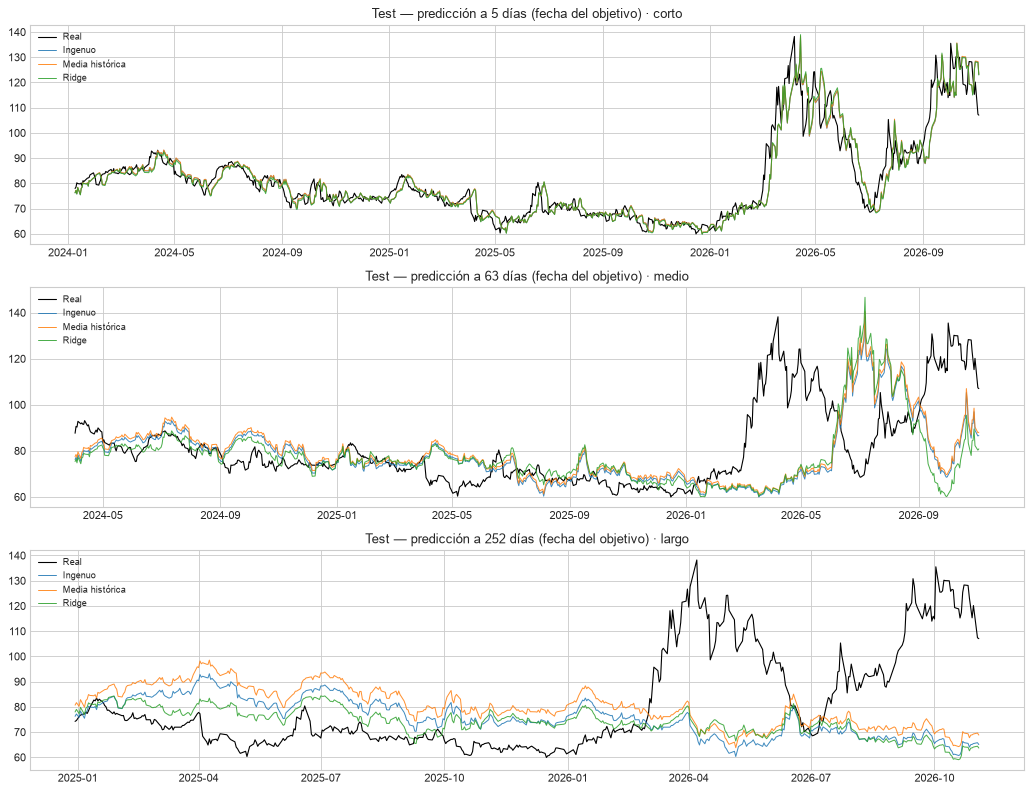

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10))
for ax, name in zip(axes, HORIZONS):
    h = HORIZONS[name]
    test, preds = test_preds[name]
    target_dates = index[test + h]
    ax.plot(target_dates, price[test + h], color="k", lw=1, label="Real")
    for model, r in preds.items():
        ax.plot(target_dates, price[test] * np.exp(r), lw=0.9, alpha=0.85, label=model)
    ax.set_title(f"Test — predicción a {h} días (fecha del objetivo) · {name}")
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()

## 5. La "trampa del nivel": por qué el gráfico bonito engaña

Un error frecuente es entrenar la red sobre el **precio** escalado y mostrar un gráfico predicción-vs-real casi perfecto. Ese gráfico se obtiene también **sin modelo**: basta con copiar el precio de hoy. Lo comprobamos con el ingenuo a 5 días.

R² del modelo ingenuo a 5 días en test: 0.873  ← parece un modelo excelente, pero no hace nada


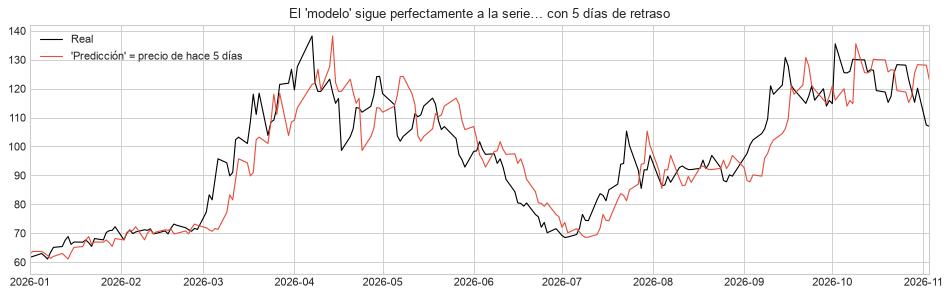

In [9]:
h = HORIZONS["corto"]
test, _ = test_preds["corto"]
p_true, p_naive = price[test + h], price[test]
r2 = 1 - np.sum((p_true - p_naive) ** 2) / np.sum((p_true - p_true.mean()) ** 2)
print(f"R² del modelo ingenuo a 5 días en test: {r2:.3f}  ← parece un modelo excelente, pero no hace nada")
fig, ax = plt.subplots(figsize=(12, 3.8))
dates = index[test + h]
ax.plot(dates, p_true, color="k", lw=1, label="Real")
ax.plot(dates, p_naive, color="#e74c3c", lw=1, label="'Predicción' = precio de hace 5 días")
ax.set_xlim(pd.Timestamp("2026-01-01"), dates[-1]); ax.legend()
ax.set_title("El 'modelo' sigue perfectamente a la serie… con 5 días de retraso")
plt.tight_layout()

Por eso en este trabajo:
- se predicen **retornos**, no niveles;
- toda métrica se acompaña de la **mejora frente al ingenuo**;
- se usa el contraste de **Diebold-Mariano** para no confundir ruido con mejora real.

## 6. Conclusiones: el listón para las redes

| Horizonte | RMSE ingenuo (validación / test) | Ridge en validación | Ridge en test | Diebold-Mariano (test) |
|---|---|---|---|---|
| Corto (5 d) | 4,1 $ / 5,8 $ | +0,4 % | −0,1 % | p = 0,92 |
| Medio (63 d) | 15,0 $ / 20,1 $ | +0,6 % | −7,2 % | p = 0,26 |
| Largo (252 d) | 29,7 $ / 25,8 $ | +2,7 % | **+5,5 %** (dirección 75 %) | p = 0,17 |

*(Mejora del RMSE frente al ingenuo; positivo = mejor.)*

- **A 5 días nada bate al ingenuo**: es la consecuencia directa de que los retornos diarios no tengan memoria (notebook 02).
- **A 252 días aparece algo de señal**: con las variables seleccionadas en el notebook 03, el Ridge mejora al ingenuo en validación (+2,7 %) y en test (+5,5 %, acertando la dirección el 75 % de las veces). Con las variables iniciales (antes del feature engineering) no lo conseguía, así que la selección aporta. **Aun así no es estadísticamente significativo** (p = 0,17): a un año vista, 2024-2026 contiene muy pocas observaciones independientes.
- **A 63 días el Ridge empeora en test (−7 %)**: el shock de Ormuz de 2026 cae de lleno en ese horizonte y ninguna variable del pasado lo anticipaba.
- El mejor `alpha` es siempre muy alto: con esta información, lo óptimo es **predecir poco movimiento** y dejar que solo las señales más robustas muevan la predicción.
- La **media histórica** empeora a largo plazo (−6 % en validación): la "tendencia alcista" de 2000-2018 no se cumplió después.

**Implicaciones para las redes (siguiente fase):**
1. El listón es el ingenuo, y el **Ridge** es la referencia justa para responder a la pregunta: *¿aportan la no linealidad y la memoria de RNN/LSTM/GRU algo más que un modelo lineal con la misma información?*
2. Mucha regularización (dropout, pocas unidades, *early stopping*): el riesgo principal es sobreajustar ruido.
3. Donde no haya mejora, el valor de la herramienta estará en el **rango de incertidumbre** y en la explicación, y así se dirá en la app y en la presentación ("en qué horizontes aporta valor y en cuáles no").